# News Q&A with Hybrid RAG
A retrieval-augmented generation (RAG) system that answers questions about news and recommends the articles it used. It is built on the Microsoft News Dataset (MIND), limited to the "news" and "finance" categories.

**Key components:**
- Hybrid search in Pinecone: finance-tuned dense embeddings (FinLang) combined with SPLADE sparse vectors
- An LLM extracts metadata (subcategory, named entities) from the query to build filters, with three fallback levels
- GPT-4o mini writes a conversational answer plus a structured list of source articles (title, URL, summary)
- Evaluation with click-based retrieval metrics and an LLM judge for relevance and groundedness

## Table of Contents
 1. [Dataset Sourcing](#dataset)
 2. [Problem Definition](#problem-definition)
 3. [Approach and Pipeline](#approach-and-pipeline)
 4. [Implementation](#implementation)
 5. [Evaluation](#evaluation)
 6. [Recommendations](#recommendations)

### Dataset Sourcing <a class="anchor" id="dataset"></a>

For this project I've selected the [**MIcrosoft News Dataset (MIND)**](https://msnews.github.io/) to build a retrieval-augmented generation (RAG) system. MIND is a large-scale dataset of 160k English news articles and 15 million user behaviour logs curated specifically for recommendation tasks. Given the time limitation, I've opted for a smaller version of the MIND dataset with randomly sampled 50,000 users and their behaviour logs and corresponding news.

**Main reasons behind the choice** of the MIND dataset:
- The dataset's rich textual content including title, abstract, body, category and entities, makes it suitable for NLP-related tasks, e.g. semantic search, information retrieval and question answering.
- The dataset is not limited to one specific domain and covers a variety of topics. In this case study, to focus on business news and financial information, I limited the scope to "news" and "finance" categories only.
- The dataset has user interaction data that allows us to explore ways to evaluate retrieval quality.

### Problem Definition <a class="anchor" id="problem-definition"></a>

**Problem:** The current abundance of available content and news makes it extremely time-consuming and overwhelming to find and process relevant information, especially when it comes to time-sensitive material like news articles. This issue is significant because access to reliable and timely news and data is essential for making data-driven decisions.

**How a Q&A RAG could add to solution**: Having a tool that retrieves relevant articles based on the user's question, summarizes them, and provides a concise, document-based response would save time and reduce cognitive overload.

### Approach and Pipeline <a class="anchor" id="approach-and-pipeline"></a>

**Approach**

This project is a Retrieval-Augmented Generation (RAG) Q&A based on news articles. It offers a conversational reply with an answer to the user's question and lists a selection of news articles that can be seen as recommendations: each has a URL link and a short summary.

**Tools & frameworks**

For its development I've used the following models, tools and frameworks:

- **LangChain** as a framework to manage document preparation, embedding generation and vector store indexing, as well as retrieval and integrating LLMs for zero-shot classification, text generation and evaluation
- **Pinecone** as vector database used for storing and retrieving documents (in this case news articles) and its Python **pinecone** library
- **Sentence Transformers** library to calculate dense vectors
- Hybrid search using **dense** and **sparse vectors** calculated using:
    - [finance-embeddings-investopedia](https://huggingface.co/FinLang/finance-embeddings-investopedia) model with the embedding size of 768 for embedding dense vectors. This model was funetuned for finance application by the FinLang team
    - Sparse Lexical and Expansion model, or [SPLADE](https://github.com/naver/splade) for getting BERT-enriched sparse vectors
- **Llama 3.2 3B** model used locally via **Ollama** for Zero-shot classification and generating potential user queries
- OpenAI's **GPT-4o mini** model used to generate RAG reply (a combination of structured and conversational response) as an answer to the user's input and for RAG Evaluation
- **pydantic** library to get structured outputs from the language models
- **wordninja** library to split concatenated words in subcategories labels

**Main Distinctive Features**
- **Zero-shot classification with LLM** for metadata filtering at retrieval stage

 Zero-shot classification is carried out utilizing **Llama 3.2 3B** model via **Ollama** with structured output via Pydantic BaseModel. It is applied to infer from user queries key metadata like subcategories and named entities that can be used for metadata filtering when retrieving relevant documents from the Pinecone index. It helps improve search relevance and reduces unnecessary processing. However, given that Pinecone (unlike, e.g. Elasticsearch) doesn't allow to use boosting or "should"-type filtering, in order to counteract potentially limiting effects of the filters, the filtering is done in three steps with gradually less strict filters to allow for a broader spectrum of candidates.

- **Hybrid search** (dense and sparse embeddings) using **Pinecone** index

 The retrieval step is performed using a hybrid vector search. The choice of **Pinecone** as a vector database is due to both its low-latency retrieval and the option of using SPLADE for hybrid search. Combining dense vectors (in our case, **finance-embeddings-investopedia** with 768 dimensions) and **SPLADE** (Sparse Lexical and Expansion) vectors enhances RAG by leveraging the strengths of both semantic and lexical retrieval. Dense vectors capture deep contextual meanings, improving recall for queries with complex or implicit intent, while SPLADE expands sparse keyword representations, ensuring precise keyword matching.

 The choice of the **finance-embeddings-investopedia** model was dictated by the chosen categories of the news articles: news and finance. This model was finetuned on the Investopedia embedding dataset for tasks like clustering or semantic search in RAG.

- **Conversational and structured AI output**

 The final AI output generated with **OpenAI's GPT-4o mini model** combines a conversational user-friendly reply and a structured part with detailed information about each article used for the reply and thus recommended to the user (title, URL, summary).

- **Evaluation chain to evaluate RAG's performance**

 The output of the RAG is evaluated with the use of **LangChain chain** with the use of **Llama 3.2 3B** model. The output of the evaluation gives a verdict on the documents' relevancy, groundedness of the reply, overall score of the output and a brief reasoning.


**Pipeline**
1. **Dataset EDA, Cleanup and Feature Engineering**:
    - Basic EDA and cleanup (nulls, duplicates)
    - Splitting subcategories tags into meaningful words using *wordninja* library
    - Processing json-like fields with named entities extracted from news titles and abstracts to get a list of labels with a high level of confidence
    - Processing interaction data and merging it with news to prepare a dataframe for retrieval evaluation based on browsing history and generated user query
2. **Build the index**: News articles data is embedded into dense and sparse vectors, and sent to Pinecone along with metadata
3. **User query processing**: The zero-shot classifier extracts from the user's query metadata that can be used to construct filters at the retrieval stage
4. **Retrieval**: The system retrieves documents about the most relevant videos for the user's query using metadata filters (3 sets of filters of varying strictness), semantic search with dense vectors and lexical search with enriched sparse vectors
5. **Generation**: The system takes a user query and a list of retrieved documents, and outputs a conversational response and a curated list of the top 3-5 sources with their URLs and short summary
6. **Evaluation**:
    - Retrieval Evaluation with Precision@K and Recall@K
        - Generating a potential user query for a given impression based on the user's latest browsing history
        - Retrieving top 100 documents with this query
        - Calculating Precision@K and Recall@K for retrieved documents taking user's positive impressions as reference
    - RAG evaluation using LLM

        Another LLM chain takes the user query, retrieved documents and RAG reply as input and evaluates the document relevancy, groundedness of the reply and overall quality of the RAG output.

### Implementation <a class="anchor" id="implementation"></a>

In [ ]:
#libraries
import os
import pandas as pd 
import numpy as np
import pinecone
import time
import torch
from sentence_transformers import SentenceTransformer
from pinecone_text.sparse import SpladeEncoder
from langchain_core.documents import Document
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate
from typing import List
from pydantic import BaseModel as PydanticBaseModel
from pydantic import Field
from tenacity import(
    retry,
    stop_after_attempt,
    wait_random_exponential
)
import wordninja
import itertools
import json
from functools import reduce
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
#options
device = 'cuda' if torch.cuda.is_available() else 'cpu'
pd.set_option('chained_assignment',None)

#### Dataset EDA, Cleanup and Feature Engineering

##### News dataframe

In [2]:
#load the news data
news_df = pd.read_csv('data/train/news.tsv', sep='\t', header=None, names=['id', 'category', 'subcategory', 'news_title', 'news_abstract', 'url', 'entities_title', 'entities_abstract'])

In [3]:
news_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51282 entries, 0 to 51281
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   id                 51282 non-null  object
 1   category           51282 non-null  object
 2   subcategory        51282 non-null  object
 3   news_title         51282 non-null  object
 4   news_abstract      48616 non-null  object
 5   url                51282 non-null  object
 6   entities_title     51279 non-null  object
 7   entities_abstract  51278 non-null  object
dtypes: object(8)
memory usage: 3.1+ MB


In [5]:
#check available categories
news_df.category.value_counts()

category
news             15774
sports           14510
finance           3107
foodanddrink      2551
lifestyle         2479
travel            2350
video             2068
weather           2048
health            1885
autos             1639
tv                 889
music              769
movies             606
entertainment      587
kids                17
middleeast           2
northamerica         1
Name: count, dtype: int64

In [6]:
#leave only news and finance
news_specialized_df = news_df[news_df['category'].isin(['news', 'finance'])]

In [7]:
news_specialized_df.shape

(18881, 8)

In [9]:
#check for nulls
news_specialized_df.isna().sum()

id                     0
category               0
subcategory            0
news_title             0
news_abstract        630
url                    0
entities_title         0
entities_abstract      1
dtype: int64

In [12]:
#given that we'll be using news abstract as document body and the percentage of nulls is low, let's drop all rows with null values
news_specialized_df.dropna(inplace=True)

In [ ]:
#check for duplicates
news_specialized_df.duplicated().any()

False

In [23]:
news_specialized_df.head(2)

,id,category,subcategory,news_title,news_abstract,url,entities_title,entities_abstract
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
7,N59295,news,newsworld,Chile: Three die in supermarket fire amid prot...,Three people have died in a supermarket fire a...,https://assets.msn.com/labs/mind/AAJ43pw.html,"[{""Label"": ""Chile"", ""Type"": ""G"", ""WikidataId"":...","[{""Label"": ""Santiago"", ""Type"": ""G"", ""WikidataI..."


The subcategories appear as tags or concatenated words. In order to use them later for filtering, we need to split them into real words.

One way to do it is to use a lightweight probabilistic segmentation with he *wordninja* library. It seems to be the best solution here given that the subcategories use rather common and potentially easily segmentable words.

In [25]:
#using lightweight probabilistic segmentation with wordninja
news_specialized_df.loc[:, "subcategory"] = news_specialized_df.loc[:,"subcategory"].apply(lambda x: ' '.join(wordninja.split(x)))

The named entities already extracted by the authors of the dataset also need transforming in order to be used. Let's combine labels from both titles and abstracts that have a confidence score greater than 95%.

In [26]:
def parse_and_filter_entities(entities_string):
    try:
        entities = json.loads(entities_string)
        labels = [item['Label'] for item in filter(lambda a: a['Confidence'] > 0.95, entities)]
    except:
        labels = []
    return labels

#parse entities fields as json and combine those for titles and abstracts in one field
news_specialized_df["entities"] = news_specialized_df[['entities_title', 'entities_abstract']]\
                                .apply(lambda x: list(set(reduce(lambda a, b: a+b, list(map(parse_and_filter_entities, x))))), axis=1)

##### Interaction dataframe

In [16]:
#load users behaviour data
interactions_df = pd.read_csv('data/train/behaviors.tsv', sep='\t', header=None, names=['impression_id', 'user_id', 'time', 'history', 'impressions'])

In [17]:
interactions_df.shape

(156965, 5)

In [18]:
interactions_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156965 entries, 0 to 156964
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   impression_id  156965 non-null  int64 
 1   user_id        156965 non-null  object
 2   time           156965 non-null  object
 3   history        153727 non-null  object
 4   impressions    156965 non-null  object
dtypes: int64(1), object(4)
memory usage: 6.0+ MB


In [19]:
#check nulls
interactions_df.isna().sum()

impression_id       0
user_id             0
time                0
history          3238
impressions         0
dtype: int64

In [20]:
#given that we'll need history to create potential user queries, and the percentage of nulls is low, let's drop all rows with null values
interactions_df.dropna(inplace=True)

In [21]:
#check duplicates
interactions_df.duplicated().any()

False

One of potential ways of evaluating the retrieval quality with this dataset is generating potential user queries based on the user's latest browsing history (assuming that they would continue navigating the same topic), retrieving documents based on these queries and calculating precision@K and recall@K taking positive impressions as reference.
In order to prepare the data for potential user query generation and metrics calculations we need to carry out a series of transformations on the interactions dataframe.

In [24]:
interactions_df.head(2)

,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...


In [27]:
#transform a string with impressions into a list
interactions_df['impressions_list'] = interactions_df.impressions.str.split(' ')

In [28]:
#extract news_id and click / non click as separate fields
interactions_df['impression_news_id'] = interactions_df.impressions_list.apply(lambda x: [item[:-2] for item in x])
interactions_df['click'] = interactions_df.impressions_list.apply(lambda x: [item[-1] for item in x])

In [ ]:
#get a new dataset with click / non click as level of aggregation
for_testing = interactions_df.explode(['impression_news_id', 'click'])

In [30]:
#leave only impressions with positive clicks from the mind small database with business and news articles only
for_testing = for_testing.merge(news_specialized_df, how='inner', left_on='impression_news_id', right_on='id').query('click=="1"')

In [31]:
#get top 100 impressions sorted by time and number of clicked news
top_impressions = for_testing.groupby('impression_id', as_index=False)\
                    .agg({'impression_id': 'max', 'click': 'size', 'time': 'max', 'impression_news_id': lambda x: list(x), 'category': lambda x: set(x), 'subcategory': lambda x: set(x)}).sort_values(['click', 'time'], ascending=False).head(100)

In [32]:
#merge with interactions to get browsing history for top 100 impression
for_user_queries = top_impressions.merge(interactions_df, how='inner', on='impression_id')[['impression_id', 'history']]

In [33]:
#get articles' details for the browsing history
for_user_queries['browsing'] = for_user_queries['history'].str.split(' ')
for_user_queries = for_user_queries.explode('browsing').merge(news_df, how='inner', left_on='browsing', right_on='id')

In [ ]:
#get a string of news titles from the last three (maximum) consulted articles before the query that will be used later for query generation
user_queries = for_user_queries.groupby('impression_id', as_index=False).agg({'impression_id': 'max', 'news_title': lambda x: '; '.join(x[-min(3, len(x)):])})[['impression_id', 'news_title']]

#### Build the Index

In [35]:
#instantiate Pinecone client
pc = pinecone.Pinecone(api_key=os.getenv('PINECONE_API'), pool_threads=6)

In [36]:
#create index if it doesn't exist
index_name = 'mind-small'
if index_name not in pc.list_indexes().names():
        print(f"Creating {index_name} index.")
        pc.create_index(
          name=index_name,
          metric="dotproduct",
          dimension=768,
          spec=pinecone.ServerlessSpec(
                                    cloud="aws",
                                    region="us-east-1"
                                  )
        )
        while not pc.describe_index(index_name).status['ready']:
            time.sleep(1)

In [37]:
#connect to index
index = pc.Index(index_name)
print(f"Connected to {index_name}.")

Connected to mind-small.


In [38]:
#instantiate dense and sparse vector models
dense_vector_model = SentenceTransformer('FinLang/finance-embeddings-investopedia', device=device)
sparse_vector_model = SpladeEncoder(max_seq_length=512, device=device)


BertForMaskedLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly overwritten. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.


In [39]:
#prepare the data for indexing, use concatenated title and abstract as page content
data_records = news_specialized_df.to_dict('records')
data = []
for record in data_records:
    data.append({
            "id": record["id"],
            "context": f""""{record["news_title"]}\n{record["news_abstract"]}""",
            "title": record["news_title"],
            "category": record["category"],
            "subcategory": record["subcategory"],
            "entities": record["entities"],
            "sources": record["url"],
        })

In [40]:
#calculate dense and sparse embeddings and load them asyncroniously to the vector database together with associated metadata
it = iter(data)
#it = pickle.load(open('iter_pickle.pkl','br'))

In [ ]:
chunk = tuple(itertools.islice(it, 256))
while chunk:
    ids = [str(x["id"]) for x in chunk]
    contexts = [x["context"] for x in chunk]
    sources = [x['sources'] for x in chunk]
    titles = [x["title"] for x in chunk]
    categories = [x["category"] for x in chunk]
    subcategories = [x["subcategory"] for x in chunk]
    entities = [x["entities"] for x in chunk]
    
    dense_vectors = dense_vector_model.encode(contexts).tolist()
    sparse_vectors = sparse_vector_model.encode_documents(contexts)
    upsert_chunk = []

    for _id, dense_vector, sparse_vector, context, source, title, category, subcategory, entity in zip(ids,
                                                            dense_vectors,
                                                            sparse_vectors,
                                                            contexts,
                                                            sources,
                                                            titles,
                                                            categories,
                                                            subcategories,
                                                            entities
                                                            ):
        metadata = {
            "category": category,
            "subcategory": subcategory,
            "title": title,
            "context": context,
            "entities": entity,
            "source": source 
        }
        upsert_chunk.append(
            {
                "id": _id,
                "values": dense_vector,
                "sparse_values": sparse_vector,
                "metadata": metadata
            }
    )
    async_result = index.upsert(vectors=upsert_chunk, async_req=True)
    chunk = tuple(itertools.islice(it, 256))
    pickle.dump(it, open('iter_pickle.pkl', 'bw'))

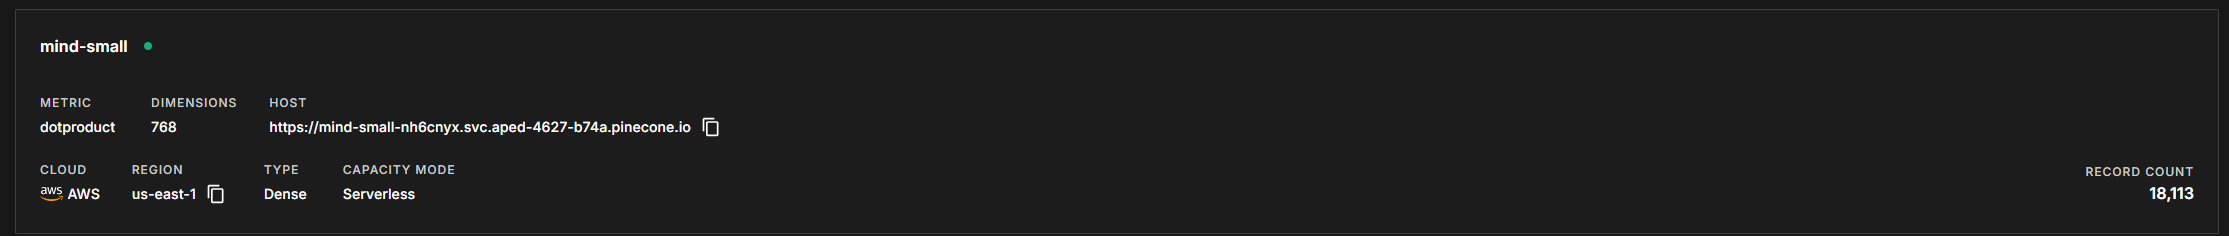

#### Candidates Retrieval and Generating RAG output <a class="anchor" id="rag"></a>

Given that the retrieval and generation parts both consist of various steps and use different LLM models (a smaller one for zero-shot classification before retrieval and a larger one for the generation part), let's define them with classes and functions for easier use.

For retrieval, we are using a hybrid approach which means that the dense and sparse vectors need to be scaled to define the weight of each vector in the final result. This is done in *encode_scale_vectors* function.

In order to construct the metadata filters we need to extract some structured data from the user's query.

In this case, let's get the subcategory and a list of keywords or named entities in the *infer_query_metadata* function. This function uses a chain with Llama 3.2 LLM and a pydantic model to validate and parse the output into typed objects.

There are 3 levels of filters defined inside the *retrieve_docs function*: from the most strict to the least restrictive in order to leverage the filters without risking retrieving zero results in case of rare queries with no matching metadata. In another VB, Elasticsearch, it could've been done using boosting or the "should" option of the filter, but in this project, I opted for Pinecone because of its integrated use of SPLADE, easy and fast setup and low retrieval latency.

In [44]:
#get a list of reference subcategories from the dataset
subcategories = news_specialized_df.subcategory.unique().tolist()

class BaseModel(PydanticBaseModel):
    class Config:
        arbitrary_types_allowed = True

#define the structure of the LLM output for inferring metadata
class QueryDetails(BaseModel):
    category: list = Field(description="List of categories of news article the user is looking for",
                          enum=subcategories)
    named_entities: list = Field(description="List of named entitites.")

In [45]:
class QARetriever():
    def __init__(self):
        self.llm = ChatOllama(model= 'llama3.2', temperature=0.0)
        self.query_structured_llm = self.llm.with_structured_output(QueryDetails)
        self.query_classification_prompt = ChatPromptTemplate.from_template(
        """
        Analyse user's query and extract the following properties:
        1. List of categories of the news the user is interested in. Choose all the best matches from this list: {subcategories}.
        2. Main named entities and keyword phrases from the user's input.
        Use only data mentioned directly in the input. Output only those properties that you are absolutely sure of based on the user's input.
        Input: {input}
        """
        )

        self.query_classification_chain = self.query_classification_prompt | self.query_structured_llm

    @retry(wait=wait_random_exponential(min=1, max=30), stop=stop_after_attempt(3))
    def infer_query_metadata(self, query):
        return self.query_classification_chain.invoke({'subcategories': subcategories, 'input': query})

    def encode_scale_vectors(self, query, alpha):
        """Encode sparse and dense vectors, and apply hybrid vector scaling using a convex combination alpha * dense + (1 - alpha) * sparse
        Args:
        alpha (float): 0 == sparse only, 1 == dense only
        """
        #create sparse query vector
        sparse = sparse_vector_model.encode_queries(query)
        #create dense query vector
        dense = dense_vector_model.encode(query).tolist()
        #scale sparse and dense vectors
        hyb_sparse = {
            'indices': sparse['indices'],
            'values':  [v * (1 - alpha) for v in sparse['values']]
        }
        hyb_dense = [v * alpha for v in dense]
        return hyb_dense, hyb_sparse

    def retrieve_from_pinecone(self, index, query, metadata_filter, top_k, alpha=0.5):
        """Retrieve top_k documents from Pinecone using metadata filters and two types of vectors.
        """
        #encode and scale the vectors
        hyb_dense, hyb_sparse = self.encode_scale_vectors(query=query, alpha=alpha)
        #retrieve documents from the VB
        retrieved_docs = index.query(
            top_k=top_k,
            vector=hyb_dense,
            sparse_vector=hyb_sparse,
            include_metadata=True,
            include_values=False,
            filter=metadata_filter
        )
        #format the documents in LangChain format
        documents = [Document(page_content=f"""News article: {item['metadata']['context']}\nTopic: {item['metadata']['subcategory']}\nKeywords{item['metadata']['entities']}""",
            metadata={"title": item['metadata']['title'],
            'source': item['metadata']['source']}) for item in retrieved_docs["matches"]]
        _ids = [item['id'] for item in retrieved_docs["matches"]]
        return documents, _ids
    
    def retrieve_docs(self, user_query, top_k=20):
        user_metadata = self.infer_query_metadata(query=user_query)
        user_category = user_metadata.category
        user_entities = user_metadata.named_entities

        metadata_filter = {
            "$and":
            
                    [
                        {"subcategory": {"$in": user_category}},
                        {"entitites": {"$in": user_entities}}]
        }

        metadata_light_filter = {
            "$or":
                    [
                        {"subcategory": {"$in": user_category}},
                        {"entitites": {"$in": user_entities}}]
        }

        #retrieve 3 batches of candidates with different filters
        retrieved_documents = []

        #with full filters applied
        retrieved_filtered_documents, _ids = self.retrieve_from_pinecone(index=index, query=user_query, metadata_filter = metadata_filter, top_k=top_k, alpha=0.5)
        retrieved_documents.extend(retrieved_filtered_documents)

        #with or-filters applied, and don't repeat already retrieved matches
        metadata_light_filter["id"] = {"$nin": _ids}
        top_k = max(3, top_k - len(_ids))
        retrieved_or_filter_documents, add_ids = self.retrieve_from_pinecone(index=index, query=user_query, metadata_filter = metadata_light_filter, top_k=top_k, alpha=0.5)
        _ids.extend(add_ids)
        retrieved_documents.extend(retrieved_or_filter_documents)

        #without filter and don't repeat already retrieved matches
        top_k = max(2, top_k - len(add_ids))
        metadata_minimal_filter = {"id": {"$nin": _ids}}
        retrieved_minimal_filter_documents, last_ids = self.retrieve_from_pinecone(index=index, query=user_query, metadata_filter = metadata_minimal_filter, top_k=top_k, alpha=0.5)
        retrieved_documents.extend(retrieved_minimal_filter_documents)
        _ids.extend(last_ids)

        return retrieved_documents, _ids


The generation part of RAG also makes use of pydantic models to validate and parse output into typed objects. A system of nested pydantic models (*Articles* and *QAOutput*) allows to output a conversational reply together with recommended sources. This way the QA functionality is combined with a recommender and also provides summarization for each source.

In [46]:
class Articles(BaseModel):
    title: str = Field(description="Title of this particular relevant article")
    source: str = Field(description="Source url of this particular relevant article")
    summary: str = Field(description="Short summary of this particular relevant article")


class QAOutput(BaseModel):
    articles: List[Articles] = Field(description="A list of recommended articles used for the answer.")
    reply: str = Field(description="A conversational output with an answer to the user's question.")

In [47]:
class QAGeneration():
    def __init__(self):
        self.rag_llm = ChatOpenAI(model_name='gpt-4o-mini', temperature=0.2, frequency_penalty = 0.1, api_key=os.getenv('OPENAI_API_KEY'))

        self.system_prompt = (
        """You are an assistant for question-answering tasks and recommending news articles. Use the following pieces of retrieved context to answer the question. {context}. If you don't know the answer, just say that you don't know. Use three sentences maximum and keep the answer concise.
        Return two things:
        1. A conversational output where you give an anwer to the user's question in one short paragraph.
        2. A list of documents, that you used to answer the question. Each document should be represnted as a json with title, source and summary. Make sure that all elements in one json come from the same document.
        """
        )

        self.qa_prompt = ChatPromptTemplate.from_messages(
            [
                ("system", self.system_prompt),
                ("human", "{input}"),
            ]
        )

        self.rag_chain_from_docs = (
                    {
                        "input": lambda x: x["input"],
                        "context": lambda x: x["context"]
                    }
                    | self.qa_prompt
                    | self.rag_llm.with_structured_output(QAOutput)
                )
        self.chain = RunnablePassthrough.assign(answer=self.rag_chain_from_docs)
        
    def get_answer(self, user_query, retrieved_documents):
        rag_output = self.chain.invoke({"input": user_query, "context": retrieved_documents})
        conv_reply = rag_output['answer'].reply
        articles = rag_output['answer'].articles
        return conv_reply, articles

#### Let's test a couple of examples

In [48]:
#instantiate the classes
qa_retriever = QARetriever()
qa_generator = QAGeneration()

In [49]:
#test 1
user_query = input('How can I help you?') #Give me information about Goldman Sachs
test1_retrieved_docs, test1_ids = qa_retriever.retrieve_docs(user_query=user_query)
test1_conv_reply, test1_articles = qa_generator.get_answer(user_query=user_query, retrieved_documents=test1_retrieved_docs)

In [50]:
print(test1_conv_reply)

Goldman Sachs is a prominent global investment banking, securities, and investment management firm known for its involvement in major corporate transactions. Recently, it has faced scrutiny over insider trading charges and criticism from political figures like Elizabeth Warren regarding bias in its financial products. Additionally, the firm has made headlines for cutting employee pay in anticipation of new tech ventures and experiencing disappointing banking revenues.


In [52]:
for article in test1_articles:
    print(f"Title: {article.title}\nSummary: {article.summary}\nSource: {article.source}\n\n")

Title: Goldman's Unwelcome Streak: A String of Insider Trading Charges
Summary: Goldman Sachs Group Inc. has built itself into a global dealmaking force whose bankers are often stitching together the biggest and most sensitive corporate transactions.
Source: https://assets.msn.com/labs/mind/AAJ2bsv.html


Title: Goldman CEO Sees Small Chance of U.S. Recession
Summary: The chances that the U.S. economy skids into a recession are 'not significant' in the near term as American households extend the expansion and trade tensions appear to be easing, according to Goldman Sachs' CEO.
Source: https://assets.msn.com/labs/mind/AAJT53C.html


Title: Goldman slashes employee pay ahead of new tech ventures
Summary: Goldman Sachs has reduced employee pay as it prepares for new technology ventures, reflecting the changing dynamics on Wall Street.
Source: https://assets.msn.com/labs/mind/AAIVrdZ.html


Title: Elizabeth Warren slams Goldman over Apple Card bias claims
Summary: Democratic presidential c

In [53]:
#test 2
user_query = input('How can I help you?') #Describe common strategies investors use in a bear market
test2_retrieved_docs, test2_ids = qa_retriever.retrieve_docs(user_query=user_query)
test2_conv_reply, test2_articles = qa_generator.get_answer(user_query=user_query, retrieved_documents=test2_retrieved_docs)

In [54]:
print(test2_conv_reply)
for article in test2_articles:
    print(f"Title: {article.title}\nSummary: {article.summary}\nSource: {article.source}\n\n")

In a bear market, investors often adopt strategies such as reallocating their portfolios to safer assets, like bonds or cash, to protect against losses. They may also engage in strategic selling to lock in profits from previous gains or to cut losses on underperforming stocks. Additionally, some investors look for opportunities in undervalued stocks or sectors that may rebound when the market stabilizes.
Title: Strong stock market may hide problems with your portfolio. Here are 5 tips to prepare
Summary: With the stock market in record-high territory, it's a good time to make sure your investments are holding their own. Consider these tips.
Source: https://assets.msn.com/labs/mind/BBWxZwd.html


Title: Jim Cramer: Time to do some strategic selling after a big run in the market
Summary: The 'Mad Money' host says the market rally creates an opportunity to make profits that can be deployed in a pullback later on.
Source: https://assets.msn.com/labs/mind/BBWqJx7.html


Title: How investors

### Evaluation <a class="anchor" id="evaluation"></a>

For the evaluation of this RAG system, I've tested out two approaches: precision and recall metrics using user behaviour data, and an LLM approach.

#### Retrieval metrics based on user behaviour

Previously, we created a dataframe containing the top 100 impression sessions, along with a string of the most recently browsed titles by the user in question. 

Now, we can utilize Llama 3.2 to generate a search query that the user is likely to type next, based on their browsing history.

In [59]:
#let's start with 50
user_queries_test = user_queries.head(50)

In [56]:
llm = ChatOllama(model='llama3.2', temperature=0.0)
query_prompt = ChatPromptTemplate.from_template(
"""
You have been given titles of articles from the user's browsing history - {input}.
Generate a search query this user is likely to use next. Output only a concise text of the query.
"""
)

query_chain = query_prompt | llm

def generate_user_query(browsing):
    llm_output = query_chain.invoke(input=browsing)
    return llm_output.content

In [60]:
#infer the queries
user_queries_test['query'] = user_queries_test['news_title'].apply(generate_user_query)

In [ ]:
user_queries_test.tail(5)

,impression_id,news_title,query
0,4765,Dog Throws A Total Tantrum When She Realizes M...,"""mom surprises daughter with stairs"""
1,6718,Airline Apologizes After False Hijack Alarm Ca...,"""Acetaminophen overdose symptoms"""
2,7519,3 students allegedly plotted to attack their m...,"""Middle school safety measures"""
3,10071,Jenelle Evans Obtains Temporary Restraining Or...,"""celebrity news"" or ""entertainment news"""
4,14861,"At height of crisis, Walgreens handled nearly ...","""opioid crisis"""


In [62]:
#retrieve top 100 documents for each generated query
user_queries_test['retrieved_ids'] = user_queries_test['query'].apply(lambda x: qa_retriever.retrieve_docs(user_query=x, top_k=100)[1])

In [63]:
#merge with real clicks data to get a reference
eval_df = user_queries_test.query('retrieved_ids.notna()').merge(top_impressions, how='inner', on='impression_id')

In [64]:
#define a function to calculate Precision@K and Recall@K
def precision_recall(retrieved_docs, clicked_docs, k):
    if k > len(retrieved_docs):
        k = len(retrieved_docs)
    top_k_docs = retrieved_docs[:k]
    #how many of the top K documents are relevant
    clicked_in_top_k = sum([1 for doc in top_k_docs if doc in clicked_docs])
    #precision
    precision = clicked_in_top_k / k
    #recall
    recall = clicked_in_top_k / len(clicked_docs)
    return precision, recall

In [65]:
#calculate precision and recall for this 100 sample
eval_df['metrics'] = eval_df[['retrieved_ids', 'impression_news_id']].apply(lambda x: precision_recall(retrieved_docs=x['retrieved_ids'], clicked_docs=x['impression_news_id'], k=100), axis=1)
eval_df['precision'] = eval_df['metrics'].apply(lambda x: x[0])
eval_df['recall'] = eval_df['metrics'].apply(lambda x: x[1])

In [69]:
eval_df[['precision', 'recall']].describe()

,precision,recall
count,50.000000,50.000000
mean,0.000600,0.006132
std,0.002399,0.026203
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,0.010000,0.142857


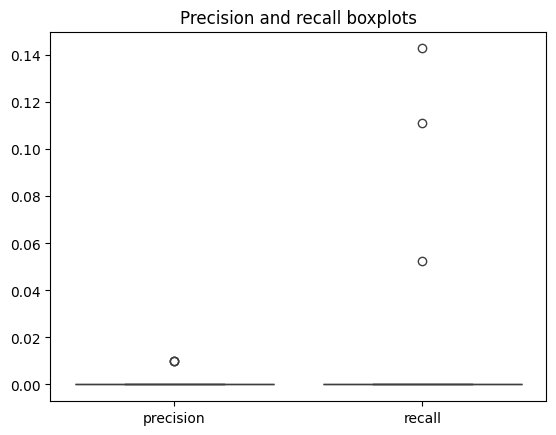

In [73]:
sns.boxplot(eval_df[['precision', 'recall']])
plt.title("Precision and recall boxplots")
plt.show()

As we can see, this approach didn't give satisfactory results. This may be due to the large pool of documents or the fact that inferring user queries from browsing history did not effectively capture the actual queries used for each search that generated impressions.

#### Evaluating RAG with LLM

Another way to evaluate RAG performance without reference data is to build another LLM chain. This chain would take the user's current query, the documents retrieved from a vector database (VB) as context, and the answer provided by the RAG system as input.

Let's assess performance on two main points:
- Relevance of the retrieved documents in relation to the query
- Groundedness of the response to check that the RAG system is actually using the retrieved documents and is not "hallucinating"

As additional data, we'll also generate a general quality score and a brief reasoning for the evaluation given.

To get uniform and structured outputs, we will once again utilize a pydantic model.

In [95]:
eval_llm = ChatOpenAI(model_name='gpt-4o-mini', temperature=0.0, api_key=os.getenv('OPENAI_API_KEY'))

class Evaluator(BaseModel):
    relevance: str = Field(description="Are the retrieved documents relevant to the question?", enum=["Yes", "No"])
    groundedness: str = Field(description="Is the answer grounded in the documents?", enum=["Yes", "No"])
    score: int = Field(description="a 1-5 score for the overall quality of the RAG output")
    reasoning: str = Field(description="Brief justification of the score")

eval_prompt = ChatPromptTemplate.from_template(
            """You are evaluating a response from a retrieval-augmented generation (RAG) system.
                Question: {query}
                Retrieved Documents:
                {contexts}
                RAG output:
                {prediction}

                Please answer the following:
                1. Are the retrieved documents relevant to the question? Output "Yes" or "No" only.
                2. Is the answer grounded in the documents? Output "Yes" or "No" only.
                3. Give a 1-5 score for the overall quality of the RAG output (1=Poor, 5=Excellent). Output only the score digit.
                4. Provide a brief justification of the score. Output one sentence maximum.

                """
        )
eval_chain = eval_prompt | eval_llm.with_structured_output(Evaluator)

def evaluate_strings(input, retrieved_docs, output):
        context = '; '.join([item.page_content for item in retrieved_docs])
        response = eval_chain.invoke({'query': input, 'contexts': context, 'prediction': output})
        return response

Let's generate and evaluate the outputs

In [90]:
#test 3
user_query = input('How can I help you?') #Give me information about Goldman Sachs
test3_retrieved_docs, test3_ids = qa_retriever.retrieve_docs(user_query=user_query)
test3_conv_reply, test3_articles = qa_generator.get_answer(user_query=user_query, retrieved_documents=test3_retrieved_docs)

In [96]:
evaluation_test3 = evaluate_strings(input=user_query, retrieved_docs=test3_retrieved_docs, output=test3_conv_reply)

In [98]:
print(f"Input: {user_query}\n")
print(f"Answer: {test3_conv_reply}\n")
for article in test3_articles:
    print(f"Title: {article.title}\nSummary: {article.summary}\nSource: {article.source}\n\n")
print(f"Relevance: {evaluation_test3.relevance}\nGroundedness: {evaluation_test3.groundedness}\nScore: {evaluation_test3.score}\nReasoning: {evaluation_test3.reasoning}")

Input: Give me information about Goldman Sachs

Answer: Goldman Sachs is a leading global investment banking, securities, and investment management firm. It has faced various challenges recently, including insider trading charges and criticism from political figures like Elizabeth Warren regarding its practices. Additionally, the firm has made headlines for slashing employee pay in light of new tech ventures and experiencing disappointing banking revenues.

Title: Goldman's Unwelcome Streak: A String of Insider Trading Charges
Summary: Goldman Sachs Group Inc. has built itself into a global dealmaking force whose bankers are often stitching together the biggest and most sensitive corporate transactions.
Source: https://assets.msn.com/labs/mind/AAJ2bsv.html


Title: Goldman CEO Sees Small Chance of U.S. Recession
Summary: The chances that the U.S. economy skids into a recession are 'not significant' in the near term as American households extend the expansion and trade tensions appear t

### Recommendations <a class="anchor" id="recommendations"></a>

#### Potential Improvements and/or Next Steps
- Using an already fine-tuned embedding model trained on financial data provided a shortcut that accelerated the development process. However, it would be beneficial to fine-tune a generic model on a subset of the MIND dataset that includes financial, business, and political news.
- Relying on only a portion of the dataset restricts the pool of available documents; thus, utilizing the entire news and finance subset of the MIND dataset would be a logical next step.
- Currently, the latency of the entire Retrieval-Augmented Generation (RAG) flow is quite high, so improving it could be a good idea.Moving it from cpu to cuda would be an easy improvement in this matter.
- Although I haven't yet utilized the knowledge graph included with the dataset, it would be worth exploring further.
- The evaluation component could be further developed. For example, LangSmith could be used for better model observability ad evaluation.
- This RAG system POC requires additional testing to enhance its robustness.
- Further work on refining prompts and testing other open-source LLM models could improve the output quality.